# Quant Course: Lesson 1


## Brownian motion and Stochastic Integrals 


### Assets and Investing


Money that is not needed for immediate consumption must be stored for future use. It can be held in several forms:

- Cash
- Savings accounts
- Investments (Government/Corporate Bonds, Stocks, Commodities, Cryptocurrencies, etc.)

Any item used to store value is called an **asset**. Some assets are **safe** (their future value is predictable), while others are **risky** and subject to large price swings.

**What is Investing?**

Investing means buying an asset expecting it to generate a positive return—either through its price increasing over time or by receiving income from it.

<img src="images/invest.png" style="float: right; margin: 0 0 15px 20px; width: 160px;" />


### Standard Market Model Assumptions

To build mathematical models of asset prices, we start by assuming an "ideal" financial world:

1. **Divisibility and Pricing**: Assets can be bought in fractions; prices are quoted per single unit.
2. **Portfolio Additivity**: Total portfolio value is simply the sum of all individual assets inside it.
3. **Frictionless Markets**: You can trade continuously at any time with zero transaction fees and zero taxes.
4. **Competitive Market (No Market Impact)**: An individual investor's trades are too small to change market prices.
5. **Zero Storage Costs / Dividends**: Holding an asset costs nothing to store, and we assume no dividends/yields are paid.

---

**Self-Financing Portfolios**

A portfolio is **self-financing** if no extra cash is added or taken out after time $t = 0$.

The change in portfolio value between time steps $t_j$ and $t_{j+1}$ comes *only* from asset price gains or losses:

$$V_{t_{j+1}} - V_{t_j} = \sum_{k} \phi_k(t_j) \left( S_k(t_{j+1}) - S_k(t_j) \right)$$

where $\phi_k(t_j)$ is the amount of asset $k$ held during that time step.

In words this says that the value of the portfolio at time $t_j+1$ is equal to the value at time $t_j$ plus the gains or losses that have been realized.

In finance, we look at value in two ways:

- **Market Price**: The actual trading price you see live on an exchange (set by supply and demand).
- **Fair Value**: The theoretical "correct" price calculated by a math model using probability ($\mathbb{Q}$-measure).








<div>
<img style="float: right;"src="images/derivative.png" width="150" />
</div>

Financial instruments are split into two major groups:

- **Cash Instruments (Underlyings)**: Stocks, Bonds, Currencies, Spot Commodities.
- **Derivative Contracts**: Forwards, Futures, Swaps, Options, Credit Derivatives.


A **derivative** is a contract whose value depends on (is derived from) an underlying asset.

- **Linear Instruments** (Forwards/Futures): Fair value can be found using basic no-arbitrage logic without modeling the exact price path.
- **Non-Linear Derivatives** (Options): Require a **stochastic model** to simulate the full random price path of the underlying asset over time.

### Motivation for Dynamic Pricing Models

**Objective**: Construct a continuous mathematical model that mimics real market price behavior (random wiggles, volatility, and continuous trend). This model will be based on **stochastic processes**.

Below is real-world historical crude oil price data:
[Trading Economics — Crude Oil](https://tradingeconomics.com/commodity/crude-oil)

<div>
<img src="images/crudeoil.jpg" width="700" />
</div>


### What is a Stochastic Process?

Intuitive ways to think about a stochastic process:
- A system evolving randomly over time.
- A function driven by randomness: $X(\cdot, \omega)$.
- A collection of different random paths or trajectories.

Heuristically : A discrete-time **stochastic process** is a sequence of random variables $\{X_t\}_{t \in T}$ defined on a probability space $(\Omega, \mathcal{F}, \mathbb{P})$, indexed by discrete time steps $T = \{0, 1, 2, \dots\}$:

$$X_0, X_1, X_2, X_3, \dots$$



### Building a Model by coin tossing

<div>
<img src="images/200ft.png" width="50" align="right" />
</div>

We start building our model using simple coin tosses, where the price changes by $+1$ or $-1$ with equal probability ($p = 0.5$).



**Construction Rules**:

1. Start at position $S_0 = 0$.
2. At step $j$, toss a fair coin:
   - **Heads** ($X_j = +1$): Price goes up by $1$.
   - **Tails** ($X_j = -1$): Price goes down by $1$.
3. Add up all previous outcomes to get current position: $S_n = \sum_{j=1}^n X_j$.
4. Repeat for $n$ total steps.

Let $X_j$ represent step $j$:

$$\mathbb{P}(X_j = +1) = 0.5, \quad \mathbb{P}(X_j = -1) = 0.5$$

The total position at step $n$ is:

$$S_n = \sum_{j=1}^n X_j, \quad \text{with } S_0 = 0$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

def randomwalk1D(n):

    coin = [-1, 1] #Tails and head

    # Randomly select either UP or DOWN
    steps = np.random.choice(coin, size=(1,n))
        
    # Sum up the values
    path = np.cumsum(steps)
    # Add the starting point
    path = np.concatenate([[0], path])
        
    return path

Matplotlib is building the font cache; this may take a moment.


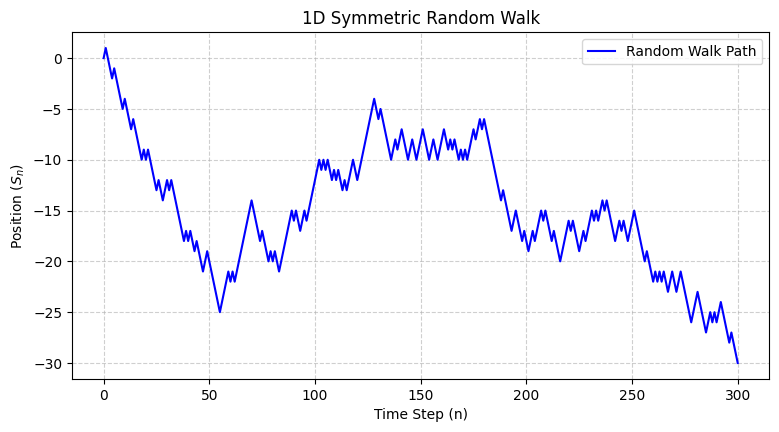

In [2]:
n_steps = 300
path = randomwalk1D(n_steps)

plt.figure(figsize=(9, 4.5))
plt.plot(path, color='b', linewidth=1.5, label='Random Walk Path')
plt.title("1D Symmetric Random Walk", fontsize=12)
plt.xlabel("Time Step (n)")
plt.ylabel("Position ($S_n$)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

### Let's look at the properties of this process:

Consider time split into steps $0=t_0 < t_1 < \dots < t_n = T$.

The discrete-time stochastic process $S_{t_0}, S_{t_1}, S_{t_2}, \dots $ satisfies for any time:
- **Independent increments**: $(S_{t_1}-S_{t_0}), (S_{t_2}-S_{t_1}), (S_{t_3}-S_{t_2}), \dots$ each step is indenpent of past moves
- **Zero Mean Increments**: On average, the change in value is zero: $E(S_{t_{i+1}}-S_{t_i})=0$
- **Variance Accumulation**: Uncertainty grows linearly with time: $Var(S_{t_{i+1}}-S_{t_i})= t_{i+1}-t_i$



In [3]:
mean = lambda x: round(np.mean(x),3)
[mean(time_slice) for time_slice in path[1:10]]

[np.float64(1.0),
 np.float64(0.0),
 np.float64(-1.0),
 np.float64(-2.0),
 np.float64(-1.0),
 np.float64(-2.0),
 np.float64(-3.0),
 np.float64(-4.0),
 np.float64(-5.0)]

In [4]:
variance = lambda x: round(np.var(x),3)
[variance(time_slice) for time_slice in path[1:10]]

[np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0)]

#### What did we miss?

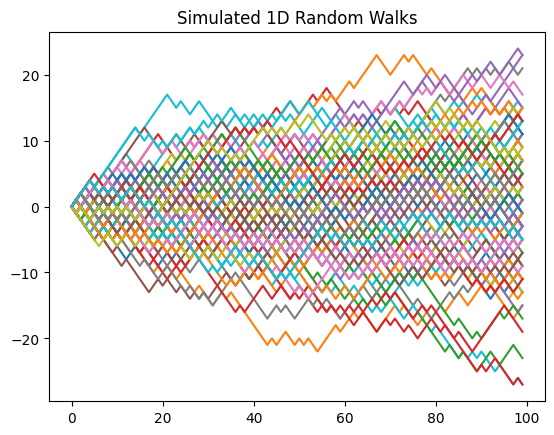

In [5]:
sim = 100
M = np.empty((sim, 0))
for k in range(0, sim, 1):
    pos_data = randomwalk1D(99)
    pos_data = np.array(pos_data).reshape(100,1)
    M = np.hstack((M,pos_data))
    
plt.plot(M);
plt.title("Simulated 1D Random Walks");

In [6]:
[mean(time_slice) for time_slice in M[1:10]]

[np.float64(0.14),
 np.float64(0.0),
 np.float64(-0.08),
 np.float64(-0.02),
 np.float64(-0.26),
 np.float64(-0.12),
 np.float64(0.02),
 np.float64(0.02),
 np.float64(0.12)]

In [7]:
[variance(time_slice) for time_slice in M[1:10]]

[np.float64(0.98),
 np.float64(1.6),
 np.float64(2.914),
 np.float64(3.96),
 np.float64(4.772),
 np.float64(5.346),
 np.float64(6.68),
 np.float64(7.16),
 np.float64(8.986)]

### Problems with the current model:
<div>
<img style="float: left;" src="images/crudeoil.jpg" width="250" />
<img style="float: right;" src="images/1Drandomwalk.png" width="250" />
</div>




While helpful as an introduction, this simple discrete walk has three major flaws for real financial modeling:

- **Discontinuous Steps**: Real asset prices move continuously over time, whereas this model forces prices to jump by rigid, fixed amounts ($\pm 1$).
- **Negative Asset Prices**: A simple random walk can drift into negative values. In real markets, stock and commodity prices are bounded below by zero due to limited liability.
- **Time-Scale Dependent**: We need a continuous-time model that remains mathematically consistent as time step size shrinks.

### Transitioning from Discrete to Continuous Time

Our coin-toss random walk moves in discrete jumps of $\pm 1$ at fixed time intervals. However, real financial markets trade continuously, and prices move in tiny, smooth increments.

To bridge this gap, we need to take a **continuum limit**:
- Divide the total time $T$ into $N$ tiny sub-intervals of length $\Delta t = \frac{T}{N}$.
- Shrink the step size $\Delta x$ alongside $\Delta t \to 0$.

How do we scale $\Delta x$ relative to $\Delta t$ so the price process doesn't explode to infinity or collapse to zero?


<div>
<img style="float: left;"src="images/sheeps.png" width="150" />
</div>

Let $S^{(N)}(t)$ be a scaled random walk over $t \in [0, T]$. We define it as:

$$S^{(N)}(t) = \sqrt{\Delta t} \sum_{j=1}^{\lfloor t/\Delta t \rfloor} X_j$$

where $X_j = \pm 1$ with equal probability $p = 0.5$.

**Why $\sqrt{\Delta t}$ instead of $\Delta t$?**
- If we scale steps by $\Delta t$, the variance drops to zero as $\Delta t \to 0$ (the path becomes a flat line).
- Scaling by $\sqrt{\Delta t}$ preserves variance equal to time $t$:

$$\text{Var}\left(S^{(N)}(t)\right) = (\sqrt{\Delta t})^2 \cdot \left\lfloor \frac{t}{\Delta t} \right\rfloor \approx \Delta t \cdot \frac{t}{\Delta t} = t$$

In [8]:
import math

def scaledrandomwalk1D(n):
    t=10
    # Generate steps for time point [1, 2, 3, ... , n*t]
    coin_scaled = [-1/np.sqrt(n), 1/np.sqrt(n)] #Tails and head with scaling
        
    # Randomly select either UP or DOWN
    steps = np.random.choice(coin_scaled, size=(1,n*t))
        
    # Sum up the values
    path = np.cumsum(steps)
    # Add the starting point
    paths = np.concatenate([[0], path])
        
    return paths

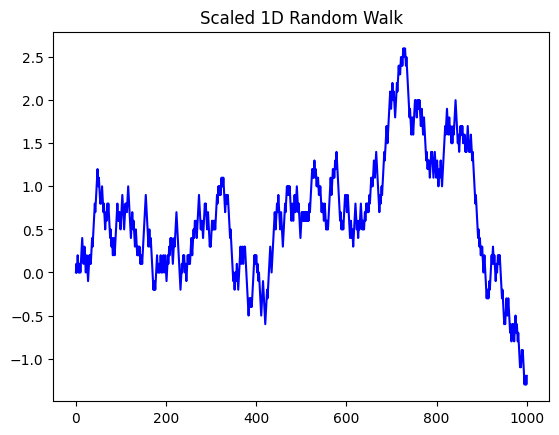

In [9]:
path = scaledrandomwalk1D(100)

plt.plot(path, 'b-')
plt.title("Scaled 1D Random Walk")
plt.show()

In [10]:
sim = 100
Mscaled = np.empty((sim, 0))
for k in range(0, sim, 1):
    pos_data = scaledrandomwalk1D(10)


In [11]:
[mean(time_slice) for time_slice in Mscaled[1:10]]

C:\Users\Temp\Git\QuantCourseBP\venv_quant_course_v312\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\Temp\Git\QuantCourseBP\venv_quant_course_v312\Lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


[np.float64(nan),
 np.float64(nan),
 np.float64(nan),
 np.float64(nan),
 np.float64(nan),
 np.float64(nan),
 np.float64(nan),
 np.float64(nan),
 np.float64(nan)]

In [12]:
[variance(time_slice) for time_slice in M[1:10]]

[np.float64(0.98),
 np.float64(1.6),
 np.float64(2.914),
 np.float64(3.96),
 np.float64(4.772),
 np.float64(5.346),
 np.float64(6.68),
 np.float64(7.16),
 np.float64(8.986)]

### Is it converging to something sensible?

As $N \to \infty$ (and $\Delta t \to 0$), the Central Limit Theorem (CLT) dictates that the sum of these tiny, independent coin flips converges to a **Normal (Gaussian) Distribution**:

$$S^{(N)}(t) \xrightarrow{d} W_ t$$

In the sense of "weak convergence of stochastic processes".The scaled random walk converges to a continuous-time stochastic process $W_t$ called **Brownian Motion** (or a **Wiener Process**).


### Definition: Standard Brownian Motion (Wiener Process)

1. **Starting Value**: $W_0 = 0$ almost surely.
2. **Continuous Paths**: The mapping $t \mapsto W_t$ is continuous everywhere.
3. **Independent Increments**: For any times $0 \le t_1 < t_2 < \dots < t_k$, the increments $(W_{t_2} - W_{t_1}), (W_{t_3} - W_{t_2}), \dots$ are mutually independent.
4. **Normally Distributed Increments**: For any $s < t$, the increment is normally distributed:
   $$W_t - W_s \sim \mathcal{N}(0, t - s)$$

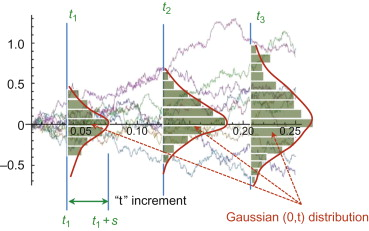
                                                                                     

### Path Properties of Brownian Motion

While Brownian motion paths are continuous everywhere, they behave very differently from standard calculus functions:

- **Nowhere Differentiable**: $W_t$ wiggles so violently at every scale that the derivative $\frac{dW_t}{dt}$ does not exist anywhere in the classical sense.



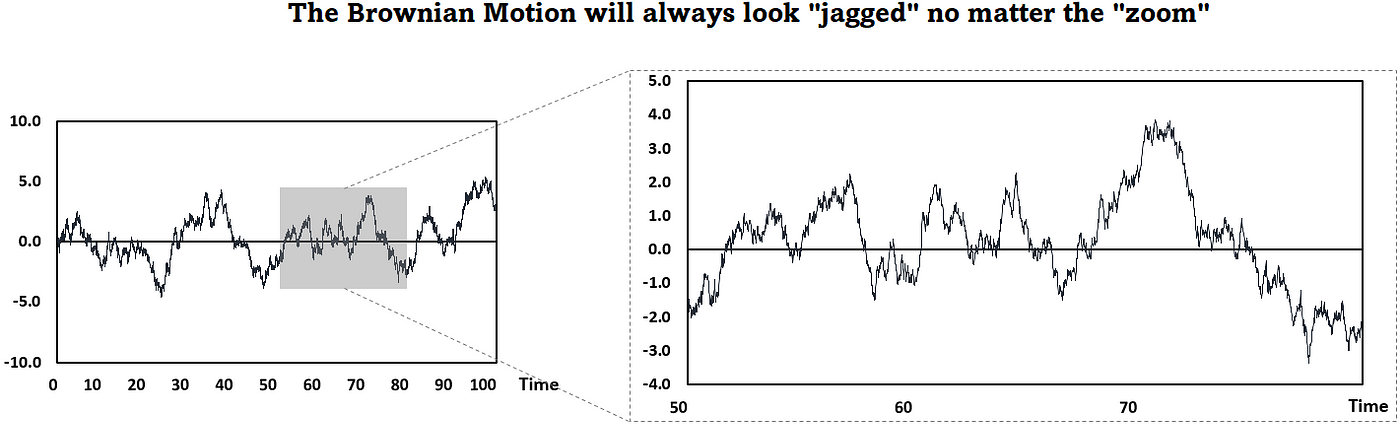

### Path Properties of Brownian Motion
- **Infinite Total Variation**: If you measure the total length of the path over $[0, T]$, it is infinite:
  $$\text{TV}(W) = \lim_{\Vert{}\mathcal{P}\Vert{} \to 0} \sum_{i=1}^n \vert{}W_{t_i} - W_{t_{i-1}}\vert{} = \infty$$
- **Finite Quadratic Variation**: Summing squared steps yields a finite, deterministic result:
  $$\langle W \rangle_T = \lim_{\Vert{}\mathcal{P}\Vert{} \to 0} \sum_{i=1}^n (W_{t_i} - W_{t_{i-1}})^2 = T$$

  This is perhaps surprising result because it can be any path. It doesn't matter how the "infinitely fast" coin flips land, the sum of the square increments will always approach the length of the interval.

In [13]:
def brownianmotion(n):
    t = 100 # time
    dt = t/n # time step

    # Simulate normal distributed variable
    steps = np.random.normal(0, np.sqrt(dt), size=(1,n-1))
        
    # Sum up the values
    path = np.cumsum(steps)
    # Add the starting point
    paths =  np.append([0],path)
        
    return paths

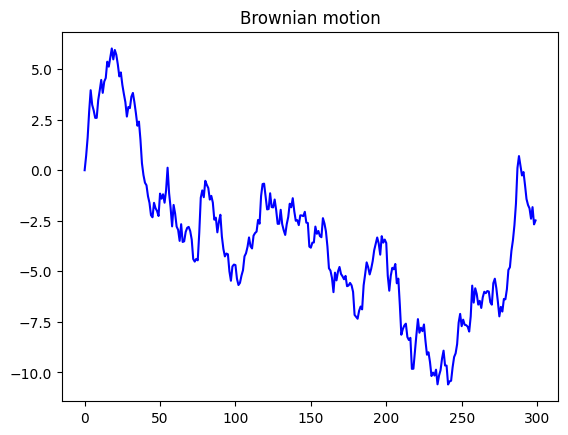

In [14]:
bm = brownianmotion(300)
plt.plot(bm, 'b-');
plt.title("Brownian motion");

In [15]:
sim = 100
bm_paths = np.empty((sim, 0))
for k in range(0, sim, 1):
    bm = brownianmotion(100)
    bm = np.array(bm).reshape(100,1)
    bm_paths = np.hstack((bm_paths,bm))

In [16]:
[mean(time_slice) for time_slice in bm_paths[1:10]]

[np.float64(0.072),
 np.float64(0.226),
 np.float64(0.367),
 np.float64(0.297),
 np.float64(0.332),
 np.float64(0.358),
 np.float64(0.391),
 np.float64(0.514),
 np.float64(0.376)]

In [17]:
[variance(time_slice) for time_slice in bm_paths[1:10]]

[np.float64(0.899),
 np.float64(2.106),
 np.float64(3.117),
 np.float64(4.094),
 np.float64(4.583),
 np.float64(5.874),
 np.float64(7.387),
 np.float64(8.357),
 np.float64(9.762)]

In [18]:
quadratic_variation = lambda x: round(np.square(x[:-1]-x[1:]).sum(),3)
[quadratic_variation(time_slice) for time_slice in bm_paths.T[:10]]

[np.float64(95.418),
 np.float64(111.825),
 np.float64(125.571),
 np.float64(108.054),
 np.float64(124.599),
 np.float64(95.934),
 np.float64(114.261),
 np.float64(100.984),
 np.float64(91.816),
 np.float64(92.852)]

### Problems with current model


| Issue | Status | Scientific Context & Mathematical Reason |
| :--- | :--- | :--- |
| **Discreteness** | **Solved** | Financial markets trade near-continuously, while coin tosses occur at rigid, discrete intervals $\Delta t$. |
| **Fixed Unit Increment** | **Solved** | Step sizes are fixed at $\pm 1$. Real asset price moves vary in magnitude and scale. |
| **Rapid Variance Growth** | **Mostly Solved** | Unscaled sums lead to variance growing linearly with time ($\text{Var}(S_n) = n$). We need proper scaling to obtain a stable limit. |
| **Ignores Trends** | **Unsolved** | Fair coin tosses ($p=0.5$) assume a zero expected return, failing to account for market drift/trends. |
| **Negative Asset Prices** | **Unsolved** | Symmetrical additive moves permit $S_n < 0$, violating the fundamental non-negativity of asset prices. |
| **Scale Invariance Failure** | **Unsolved** | Move sizes are absolute rather than relative: a 10 USD price move is just as likely for a 15 USD stock as for 250 USD stock. |





### Adding a Trend

To reflect asset growth over time, we incorporate a deterministic trend parameter along with a volatility scale into standard Brownian motion:

$$W_{t; \mu, \sigma} = \mu t + \sigma W_t$$

This process is known as **Brownian Motion with Drift**, characterized by drift parameter $\mu t$ and volatility parameter $\sigma$. 

*(Note: Parameters $\mu$ and $\sigma$ can also be time-dependent functions $\mu(t)$ and $\sigma(t)$.)*
<div>
<img src="images/browniandrift.jpg" width="450" />
</div>

##### Non-negative values and moves that scale with price level?

### Resolving Scale and Negative Prices: Log-Normal Modeling

To resolve the remaining limitations of negative prices and fixed-size dollar moves, we model the log-price process $\psi(t) = \ln(S_t)$ rather than the raw asset price $S_t$.

**Key Property: Exponential Guarantee**

Setting $S_t = e^{\psi(t)}$ mathematically guarantees that $S_t > 0$ for all $t$, satisfying the non-negativity constraint of real financial assets.



### Mechanics of Logarithmic Returns

Modeling changes in $\ln(S_t)$ converts additive steps in log-space into relative multiplicative updates in price-space.

**Mathematical Derivation**

* **Additive Log-Move**: Let $\psi(t+1) = \psi(t) + \delta$
* **Multiplicative Price Impact**:
  $$S_{t+1} = e^{\psi(t+1)} = e^{\psi(t) + \delta} = e^{\psi(t)} e^{\delta} = S_t e^{\delta}$$
* **Relative Price Change**:
  $$\Delta S_t = S_{t+1} - S_t = S_t e^{\delta} - S_t = (e^{\delta} - 1) S_t$$

> **Core Insight**: A fixed additive step $\delta$ in log-space produces a percentage move proportional to the current asset price $S_t$, fulfilling scale invariance.

Modeling log-prices $\ln(S_t)$ as a Brownian motion with drift:

$$\ln(S_t) = \ln(S_0) + \mu t + \sigma W_t$$

Exponentiating both sides yields the explicit solution for **Geometric Brownian Motion**:

$$S_t = S_0 e^{\mu t + \sigma W_t}$$

---

### Is this good enough?

In [19]:
import math

def geometricbrownianmotion(n, S0, mu, sigma, t):
    dt = t/n # time step

    # Simulate the variable
    St = np.exp(
        (mu-sigma**2/2)*dt + sigma * np.random.normal(0, np.sqrt(dt), size=(1,n)).T
    )
    #include array of 1's
    St = np.vstack([np.ones(1), St])

    # Move the object 
    St = S0 * St.cumprod(axis=0)
        
    time = np.linspace(0,t, n+1)
    
    return time, St


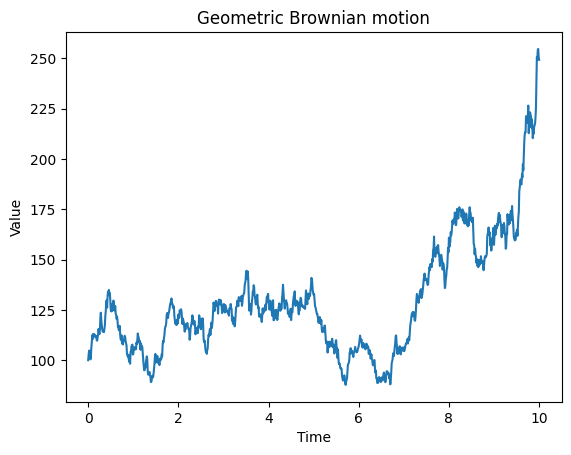

In [20]:
mu = 0.1
sigma = 0.2
S0 = 100
n = 1000 #increase n
t=10
tt, St = geometricbrownianmotion(n, S0, mu, sigma, t)
plt.plot(tt, St) ;
plt.title("Geometric Brownian motion")
plt.xlabel("Time");
plt.ylabel("Value");

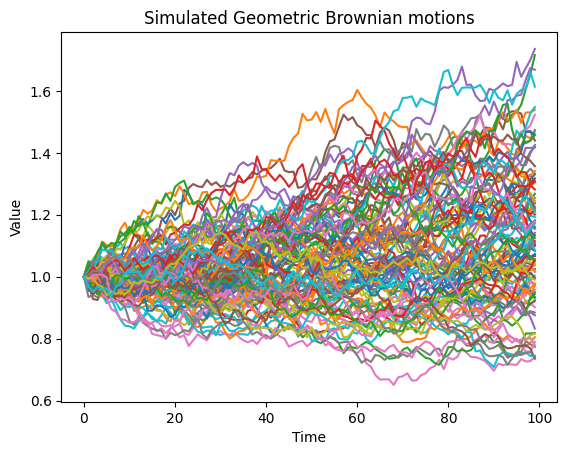

In [21]:
sim = 100
gbm_paths = np.empty((sim, 0))
for k in range(0, sim, 1):
    tt, gbm = geometricbrownianmotion(99, 1, 0.15, 0.2, 1)
    gbm_paths = np.hstack((gbm_paths,gbm))
plt.plot(gbm_paths);
plt.title("Simulated Geometric Brownian motions")
plt.xlabel("Time");
plt.ylabel("Value");

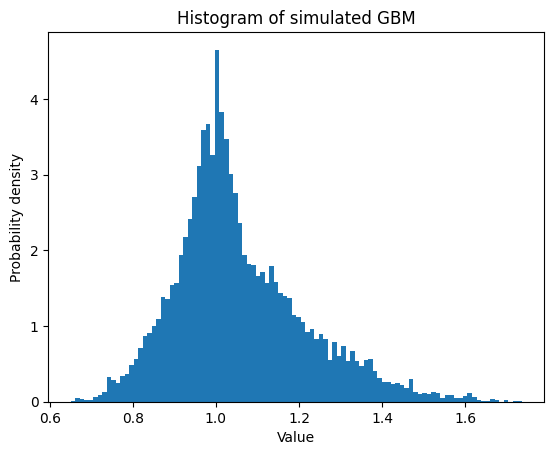

In [22]:
#plot histogram
gbm_paths = np.array(gbm_paths).reshape(sim*sim,1)
plt.title("Histogram of simulated GBM", loc='center')
plt.xlabel("Value")
plt.ylabel("Probability density")
plt.hist(gbm_paths, bins=100, density=True)
plt.show()

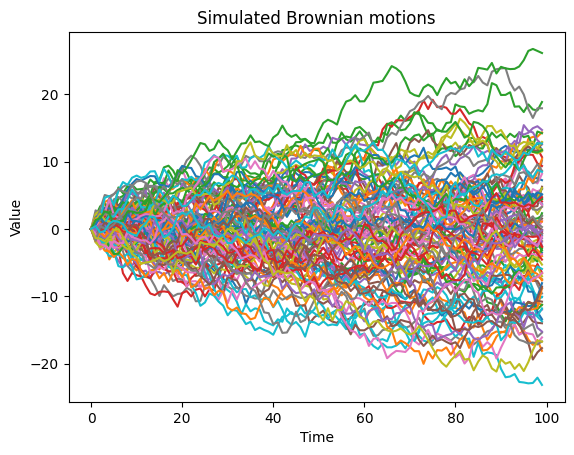

In [23]:
plt.plot(bm_paths);
plt.title("Simulated Brownian motions")
plt.xlabel("Time");
plt.ylabel("Value");

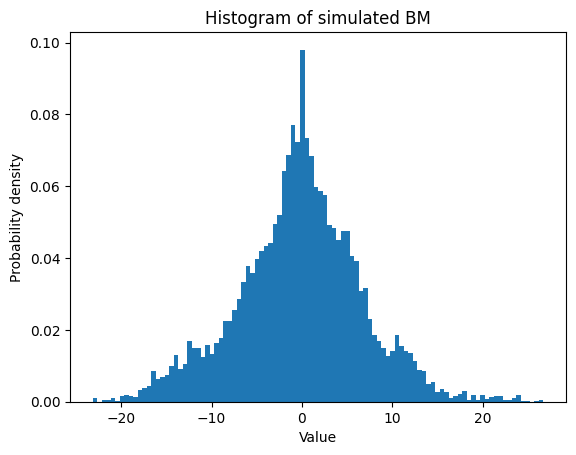

In [24]:
#plot histogram
bm_paths = np.array(bm_paths).reshape(sim*sim,1)
plt.title("Histogram of simulated BM", loc='center')
plt.xlabel("Value")
plt.ylabel("Probability density")
plt.hist(bm_paths, bins=100, density=True)
plt.show()

Initially we wanted to model the value of the portfolio.

If we take $ S_t = S_0  e^{\mu t + \sigma W_t} $ the change (**derivative**) in the asset price

$$ \frac{d S_t}{dt} = \left[ \mu + \sigma \frac{d W_t}{dt}\right] S_0  e ^{\mu t + \sigma W_t} =  \left[\mu + \sigma \frac{dW_t}{dt}\right] S_t = \mu S_t + \sigma S_t \frac{d W_t}{dt} $$




    
In differential form:

$$ d S_t = \mu S_t dt  + \sigma S_t d W_t$$

### What is the derivative of the Brownian motion?

<div>
<img style="float: right;" src="images/derivate.png" width="300"/>
<img style="float: left;" src="images/integral.png" width="300"/>
</div>

### Stochastic calculus

- Problems: When attempting to apply classical calculus to asset prices driven by Brownian motion, standard mathematical rules break down due to the extreme roughness of sample paths.
- Ordinary calculus: Differentiation (gradient) $\rightarrow$ Integration (area)
- Stochastic calculus: Ordinary calculus + randomness, Integration $\rightarrow$ Differentiation 

- How to define:
$$ \int_{0}^{T} S_t d W_t = ? $$

- Plots from *Lessons in Industrial Automation*





### Rieman approach
- $\int_{a}^b f(t)dt$
- partition: 
$$ P_{n} = \{t_{0}, t_1, \dots, t_n\} $$
- sums: 
$$L(P_n, f) = \sum_{i=1}^{n}f(t_{i-1})(t_i - t_{i-1}), U(P_n, t) = \sum_{i=1}^{n}f(t_{i})(t_i - t_{i-1})$$


### Stieltjes approach
- $g(t)$: monotonic and bounded variation
- $\int_{a}^b f(t)dg(t)$
- sums: 
$$L(P_n, f,g) = \sum_{i=1}^{n}f(t_{i-1})(g(t_i) - g(t_{i-1})) $$
$$U(P_n, f,g) = \sum_{i=1}^{n}f(t_{i})(g(t_i) - g(t_{i-1}))$$



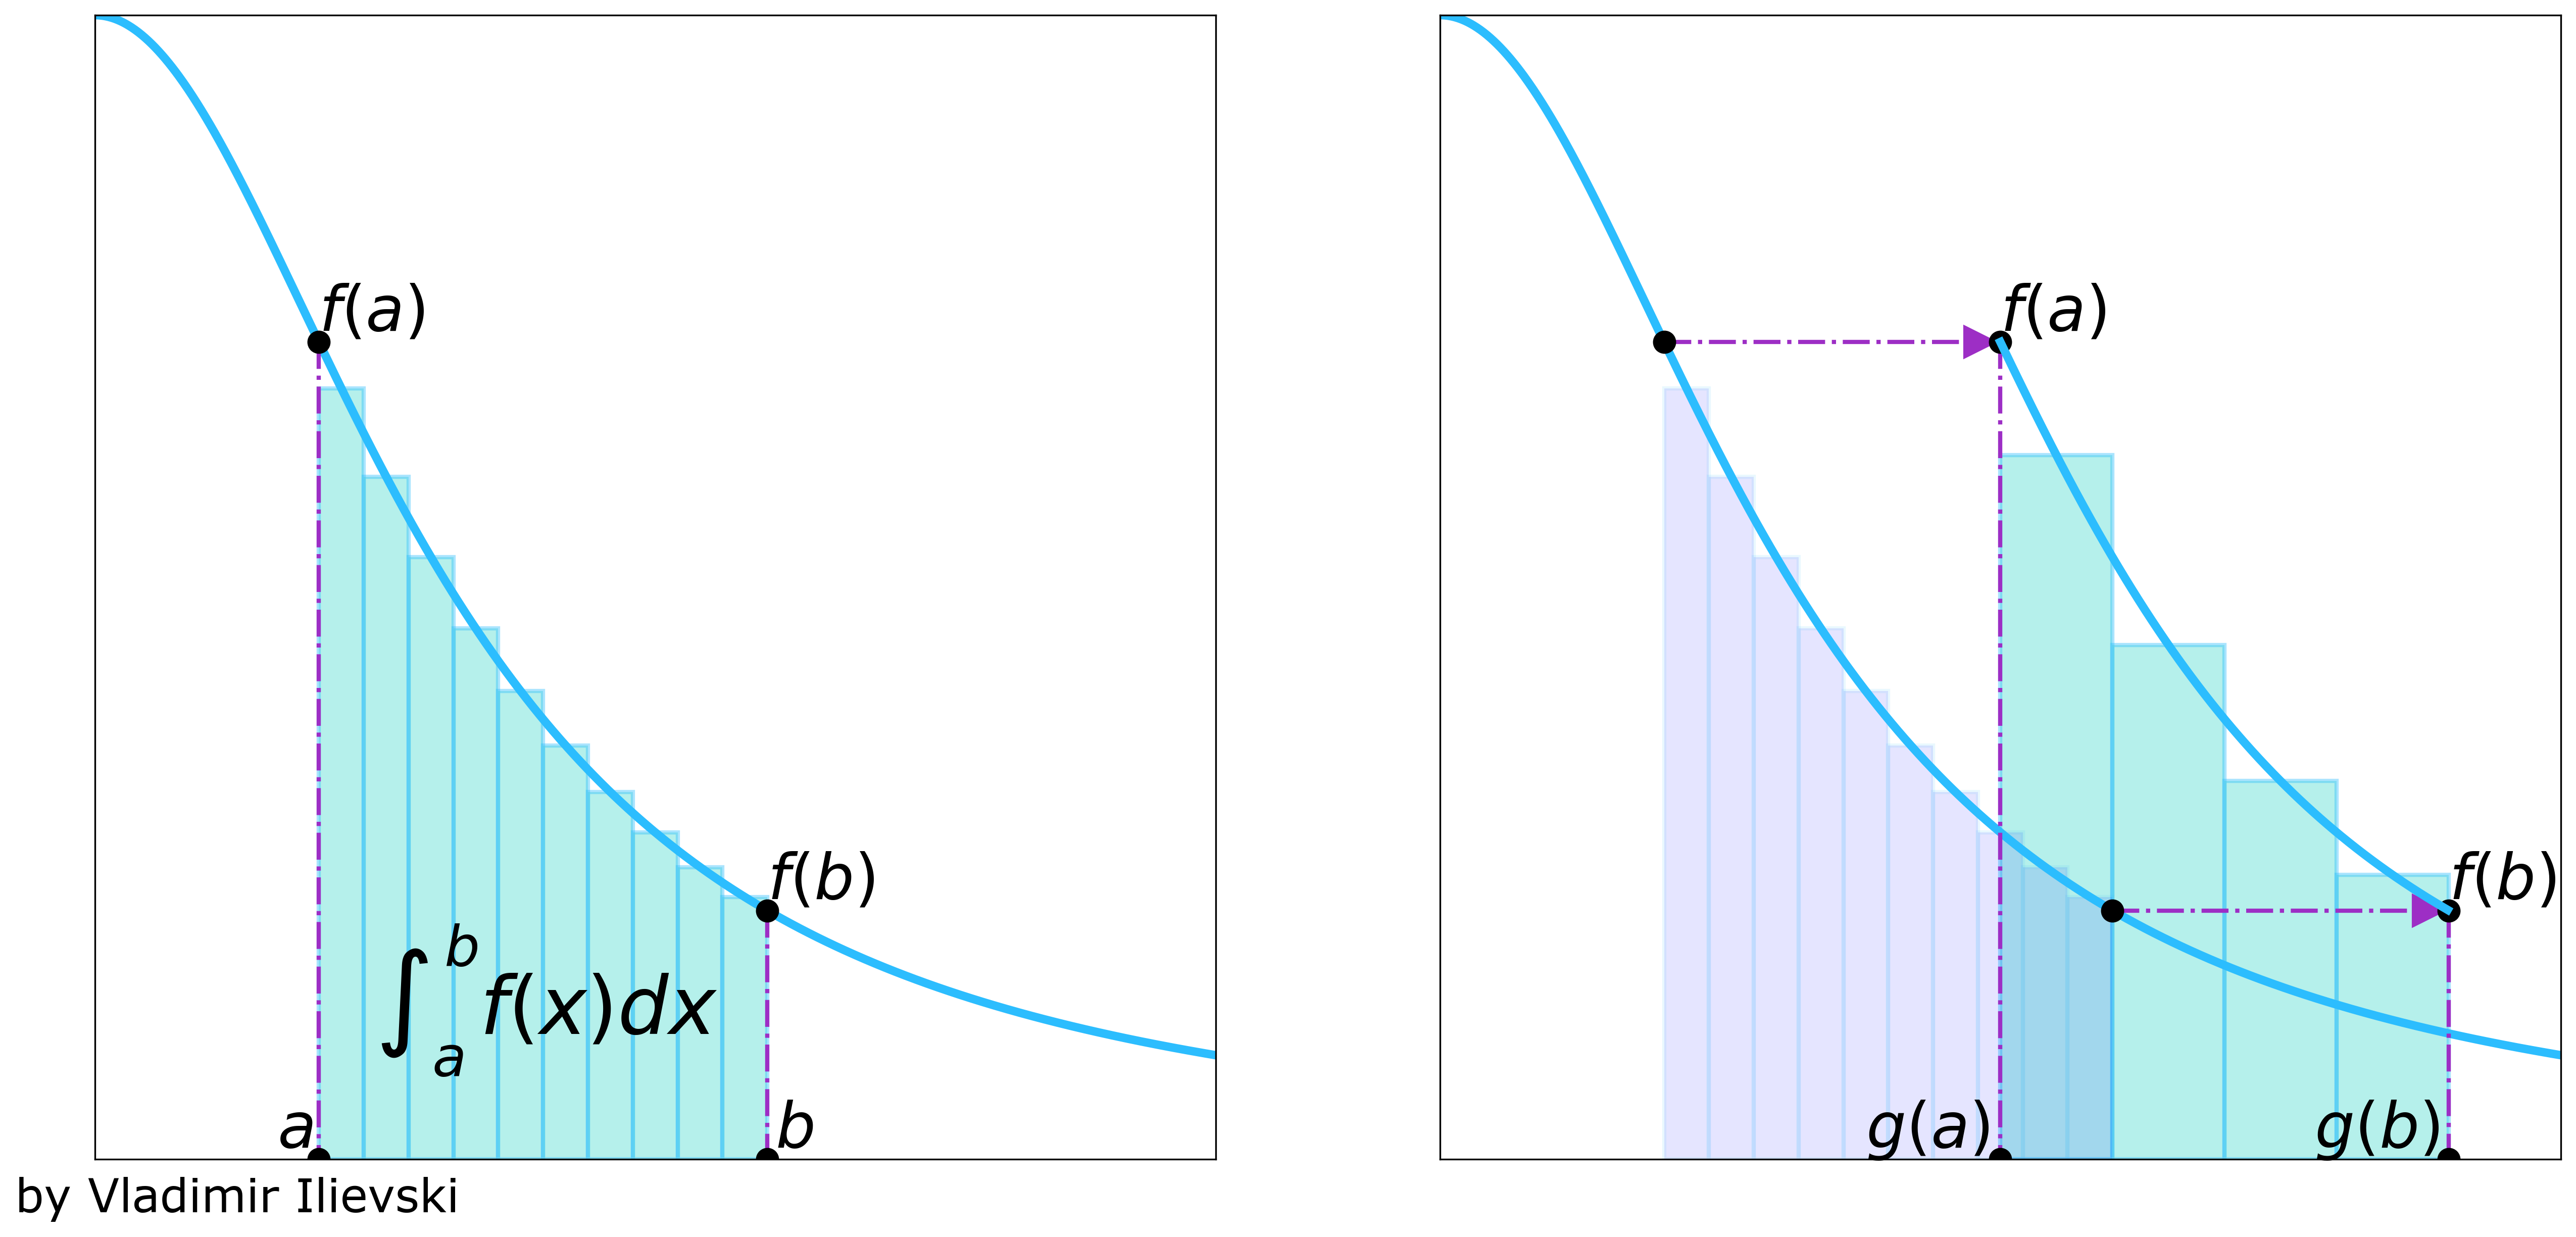

<div>
<img style="float: left;" src="images/stochasticint2.png" width="400"/>
</div>

### Stochastic integral
For any partioning $0 = t_0 < t_1 < \dots < t_n= T $ of the interval $[0, T]$ we can form the sum:

 $$ \sum_{j=0}^n f(t_j) (W_{t_{j+1}} - W_{t_j}) $$
 
Because $W_{t_{j+1}} - W_{t_j}$ are random increments, this sum **defines a random variable**. 

It can be shown that, under suitable continuity and boundedness conditions, these properties guarantee that one can indeed define a stochastic integral by the formula


$$ \int_{0}^{T} f(t) d W_t = \lim_{n \rightarrow \infty} \sum_{j=0}^n f(t_j) (W_{t_{j+1}} - W_{t_j}) $$
 
The limit is understood in the
stochastic sense of convergence in probability.

### Fundamental Rules for Stochastic Integration

Let $X_t$ and $Y_t$ be suitable stochastic processes, and let $a, b \in \mathbb{R}$ be constants:

**1. Fundamental Theorem / Telescope Rule**
The integral of a simple stochastic differential evaluates directly to the net path increment:
$$\int_0^T dW_t = W_T - W_0$$

**2. Linearity with Respect to the Integrand**
Stochastic integration preserves linear combinations of integrand processes:
$$\int_0^T (a X_t + b Y_t) \, dW_t = a \int_0^T X_t \, dW_t + b \int_0^T Y_t \, dW_t$$

**3. Linearity with Respect to the Integrator**
Linear combinations in the driving process (integrator) distribute across integrals:
$$\int_0^T X_t \, d(a Y_t + b W_t) = a \int_0^T X_t \, dY_t + b \int_0^T X_t \, dW_t$$



#### Problem: 
Calculating stochastic integrals using the limit definition is tedious, time-consuming, and often mathematically non-trivial. In ordinary calculus, we rarely compute integrals using Riemann sum definitions; instead, we use rules like the **Fundamental Theorem of Calculus** and **Taylor's Theorem**.


### Let's go back to ordinary calculus

In standard calculus, the **Fundamental Theorem of Calculus** establishes that differentiation and integration are inverse operations for a differentiable function $f(t)$:

$$f(t) = f(0) + \int_{0}^{T} f'(t) \, dt$$

Expressed in differential form:

$$df(t) = f'(t) \, dt$$

This differential form implies that a small change in $f(t)$ is directly **proportional** to a small change in $t$.

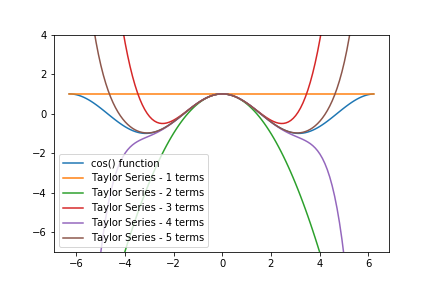



We can derive this differential relation by taking a **Taylor series expansion** of $f(t)$ around $t = a$:

$$f(t) = f(a) + (t - a) \frac{df}{dt}(a) + \frac{1}{2} (t - a)^2 \frac{d^2 f}{dt^2}(a) + \dots$$

Rewriting in terms of increments by setting $t - a = dt$ and $f(t) - f(a) = df(t)$:

$$df(t) = \frac{df}{dt}(a) \, dt + \frac{1}{2} \frac{d^2 f}{dt^2}(a) \, (dt)^2 + \mathcal{O}\left((dt)^3\right)$$

* **First-Order Dominance**: As $dt \to 0$, the second-order term $(dt)^2$ and higher-order terms vanish much faster than $dt$.
* **First-Order Differential**: Neglecting higher-order terms leaves the classical differential form:
  $$df(t) = \frac{df}{dt} \, dt$$


### Can we derive a formula for stochastic derivates in a similar way?

To derive the differential of a stochastic process $f(t, S_t)$, where $f$ is a twice-differentiable function, we start with the multi-variable **Taylor series expansion**:

$$df = \frac{\partial f}{\partial t} dt + \frac{\partial f}{\partial S_t} dS_t + \frac{1}{2}\frac{\partial^2 f}{\partial t^2}(dt)^2 + \frac{\partial^2 f}{\partial t \partial S_t} dt \, dS_t + \frac{1}{2}\frac{\partial^2 f}{\partial S_t^2}(dS_t)^2 + \dots$$



$$dS_t = \mu \, dt + \sigma \, dW_t$$

Substituting $dS_t$ into the Taylor expansion yields:

$$df = \frac{\partial f}{\partial t} dt + \frac{\partial f}{\partial S_t}(\mu \, dt + \sigma \, dW_t) + \frac{1}{2}\frac{\partial^2 f}{\partial t^2}(dt)^2 + \frac{\partial^2 f}{\partial t \partial S_t} dt(\mu \, dt + \sigma \, dW_t) + \frac{1}{2}\frac{\partial^2 f}{\partial S_t^2}\left( \mu^2 (dt)^2 + 2\mu\sigma \, dt \, dW_t + \sigma^2 (dW_t)^2 \right) + \dots$$

In stochastic calculus, second-order terms containing $(dW_t)^2$ do not vanish because Brownian motion has non-zero quadratic variation. We apply the fundamental **Itô Multiplication Rules**:

| Product | Evaluates To | Mathematical Justification |
| :--- | :--- | :--- |
| **$(dW_t)^2$** | **$dt$** | Quadratic variation of Brownian motion accumulates linearly at rate $dt$. |
| **$dt \cdot dW_t$** | **$0$** | Cross-term is of order $\mathcal{O}\left((dt)^{3/2}\right)$, vanishing in the limit. |
| **$(dt)^2$** | **$0$** | Higher-order time term vanishes as $dt \to 0$. |

Applying these multiplication rules simplifies the expanded terms:

* **First-order terms:** $\frac{\partial f}{\partial t} dt + \mu \frac{\partial f}{\partial S_t} dt + \sigma \frac{\partial f}{\partial S_t} dW_t$
* **Cross terms:** vanish ($dt \cdot dt = 0$ and $dt \cdot dW_t = 0$)
* **Second-order state term:** $\frac{1}{2} \frac{\partial^2 f}{\partial S_t^2} \left(0 + 0 + \sigma^2 dt\right) = \frac{1}{2} \sigma^2 \frac{\partial^2 f}{\partial S_t^2} dt$

Grouping deterministic ($dt$) and stochastic ($dW_t$) terms yields **Itô's Lemma**:

$$df(t, S_t) = \left( \frac{\partial f}{\partial t} + \mu \frac{\partial f}{\partial S_t} + \frac{1}{2} \sigma^2 \frac{\partial^2 f}{\partial S_t^2} \right) dt + \sigma \frac{\partial f}{\partial S_t} dW_t$$

> **Core Result**: The extra convexity term $\frac{1}{2} \sigma^2 \frac{\partial^2 f}{\partial S_t^2} dt$ represents the deterministic drift adjustment arising directly from variance in $S_t$.

Which in integral form:



$$f(S_T) = f(S_0) + \int_0^T \Big( \mu_ t f'(S_t)dt +  \frac{1}{2} \int_0^T \sigma_t^2 f''(S_t) \Big) dt + \int_0^T \sigma_ t f'(S_t)dW_t  $$

Sometimes referred as stochatic version of the chain rule.


### Let's see an example

$$\int_0^T W_t dW_t=?$$

We know that: $f(S_T) = f(S_0) + \int_0^T \Big( \mu_ t f'(S_t)dt +  \frac{1}{2} \int_0^T \sigma_t^2 f''(S_t) \Big) dt + \int_0^T \sigma_ t f'(S_t)dW_t  $




Let us represent the Brownian motion as an Ito process:

$ \mu_t = 0$, $\sigma_t=1$ and $f(t)=t^2$, $S_t=W_t$

$$W_T^2 = W_0^2 + \int_0^T \Big(  0\cdot 2 W_t  +\frac{1}{2} \int_0^T 2 \Big)dt + \int_0^T 2 W_t d W_t  $$


$W_0 = 0,  \int_0^T dt = T $, so we get:

$$\int_0^T W_t dW_t = \frac{1}{2}(W_T^2-T)$$

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Simulation Parameters
T = 1.0        # Total time
dt = 0.0005    # Fine time steps for better convergence
steps = int(T / dt)
t = np.linspace(0, T, steps)

# 2. Generate Brownian Motion (W_t)
np.random.seed(42)
dW = np.random.normal(0, np.sqrt(dt), steps)
W = np.cumsum(dW)

# 3. Target: Calculate the Integral of W_t dW_t
# We will compare the theoretical Ito result vs the 'naive' Calculus result

# A. The Itô Result (From your derivation): 0.5 * (W_t^2 - t)
ito_integral_theory = 0.5 * (W**2 - t)

# B. The 'Standard' Calculus Guess (Incorrect): 0.5 * W_t^2
standard_calc_guess = 0.5 * W**2

# C. Numerical Integration (Simulating the 'physical' process)
# Summing W_t * dW_t step-by-step
numerical_sum = np.zeros(steps)
for i in range(1, steps):
    numerical_sum[i] = numerical_sum[i-1] + W[i-1] * dW[i]



<>:2: SyntaxWarning: invalid escape sequence '\i'
<>:5: SyntaxWarning: invalid escape sequence '\i'
<>:2: SyntaxWarning: invalid escape sequence '\i'
<>:5: SyntaxWarning: invalid escape sequence '\i'
C:\Users\Temp\AppData\Local\Temp\ipykernel_8340\643127247.py:2: SyntaxWarning: invalid escape sequence '\i'
  plt.plot(t, numerical_sum, label="Numerical $\int W_t dW_t$ (Simulated)", color='black', lw=2)
C:\Users\Temp\AppData\Local\Temp\ipykernel_8340\643127247.py:5: SyntaxWarning: invalid escape sequence '\i'
  plt.title("Itô's Lemma for $\int W_t dW_t$")


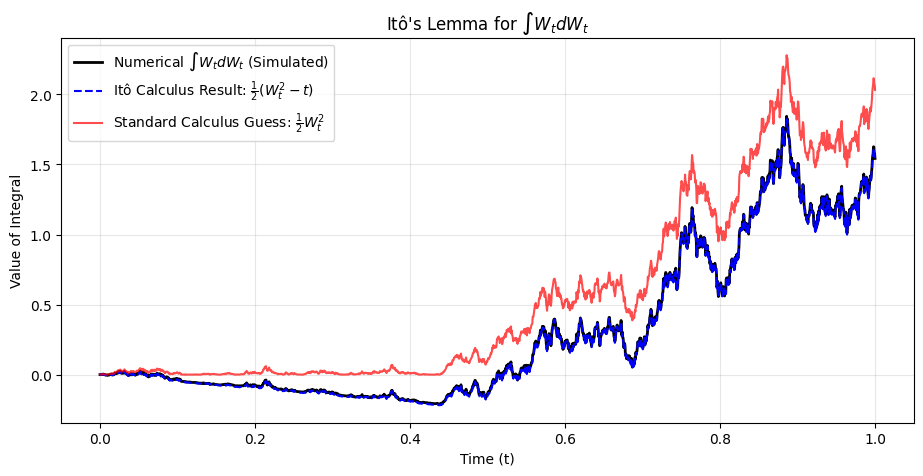

In [26]:
plt.figure(figsize=(11, 5))
plt.plot(t, numerical_sum, label="Numerical $\int W_t dW_t$ (Simulated)", color='black', lw=2)
plt.plot(t, ito_integral_theory, label="Itô Calculus Result: $\\frac{1}{2}(W_t^2 - t)$", color='blue', linestyle='--')
plt.plot(t, standard_calc_guess, label="Standard Calculus Guess: $\\frac{1}{2}W_t^2$", color='red', alpha=0.7)
plt.title("Itô's Lemma for $\int W_t dW_t$")
plt.xlabel("Time (t)")
plt.ylabel("Value of Integral")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Another example - interest rate model

To solve the Short-Rate Stochastic Differential Equation (SDE) with mean reversion:

$$dr_t = \theta(\mu - r_t) \, dt + \sigma \, dW_t$$

we use the integrating factor method by defining the process $f(t, r_t) = r_t e^{\theta t}$, with $df(t, S_t) = \left( \frac{\partial f}{\partial t} + \mu \frac{\partial f}{\partial S_t} + \frac{1}{2} \sigma^2 \frac{\partial^2 f}{\partial S_t^2} \right) dt + \sigma \frac{\partial f}{\partial S_t} dW_t$


 Computing Partial Derivatives

We compute the required partial derivatives for $f(t, r_t) = r_t e^{\theta t}$:

* **Time derivative ($\frac{\partial f}{\partial t}$)**: Treating $r_t$ as a constant:
  $$\frac{\partial f}{\partial t} = \frac{\partial}{\partial t}\left( r_t e^{\theta t} \right) = \theta r_t e^{\theta t}$$
* **State derivative ($\frac{\partial f}{\partial r}$)**: Treating $t$ as a constant:
  $$\frac{\partial f}{\partial r} = \frac{\partial}{\partial r}\left( r_t e^{\theta t} \right) = e^{\theta t}$$
* **Second state derivative ($\frac{\partial^2 f}{\partial r^2}$)**: Taking the derivative of $e^{\theta t}$ with respect to $r$:
  $$\frac{\partial^2 f}{\partial r^2} = \frac{\partial}{\partial r}\left( e^{\theta t} \right) = 0$$

> **Key Observation**: Because $\frac{\partial^2 f}{\partial r^2} = 0$, the quadratic variation term $\frac{1}{2}\frac{\partial^2 f}{\partial r^2}(dr_t)^2$ in Itô's Lemma vanishes completely, simplifying the differential expansion.

Substituting the partial derivatives into Itô's expansion:

$$d(r_t e^{\theta t}) = \frac{\partial f}{\partial t} dt + \frac{\partial f}{\partial r} dr_t + \frac{1}{2} \frac{\partial^2 f}{\partial r^2} (dr_t)^2$$

$$d(r_t e^{\theta t}) = \left(\theta r_t e^{\theta t}\right) dt + e^{\theta t} \left[\theta(\mu - r_t) \, dt + \sigma \, dW_t\right]$$

Expanding terms:

$$d(r_t e^{\theta t}) = \theta r_t e^{\theta t} \, dt + \theta \mu e^{\theta t} \, dt - \theta r_t e^{\theta t} \, dt + \sigma e^{\theta t} \, dW_t$$

Canceling the linear drift terms $\pm \theta r_t e^{\theta t} \, dt$ yields:

$$d(r_t e^{\theta t}) = \theta \mu e^{\theta t} \, dt + \sigma e^{\theta t} \, dW_t$$
 


Integrating both sides from $t = 0$ to $t = T$:

$$r_T e^{\theta T} - r_0 = \int_0^T \theta \mu e^{\theta t} \, dt + \int_0^T \sigma e^{\theta t} \, dW_t$$

Evaluating the deterministic integral $\int_0^T \theta \mu e^{\theta t} \, dt = \mu (e^{\theta T} - 1)$:

$$r_T e^{\theta T} = r_0 + \mu (e^{\theta T} - 1) + \sigma \int_0^T e^{\theta t} \, dW_t$$

Multiplying through by $e^{-\theta T}$ gives the **exact closed-form solution**:

$$r_T = r_0 e^{-\theta T} + \mu \left(1 - e^{-\theta T}\right) + \sigma \int_0^T e^{-\theta (T - t)} \, dW_t$$



| Term / Property | Asymptotic Behavior ($T \to \infty$) | Financial & Mathematical Interpretation |
| :--- | :--- | :--- |
| **Initial Memory** ($r_0 e^{-\theta T}$) | $e^{-\theta T} \to 0$ | The memory of the starting interest rate $r_0$ decays exponentially over time. |
| **Mean Reversion** ($\mu (1 - e^{-\theta T})$) | $(1 - e^{-\theta T}) \to 1$ | Ensures that the long-run expected average value of the process approaches $\mu$. |
| **Stochastic Term** ($\sigma \int_0^T e^{-\theta (T-t)} dW_t$) | $\mathbb{E}\left[\text{Integral}\right] = 0$ | The Itô integral has expectation 0, driving variance without affecting long-term mean. |


In [31]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parameters for the OU 
r0 = 0.03      # Initial Interest Rate (3%)
theta = 0.1    # Rate of mean reversion (how fast it pulls back)
mu = 0.05      # The "Long-term" mean rate (5%)
sigma = 0.02   # Volatility
T = 5.0        # Simulate over 5 years
dt = 0.01
steps = int(T / dt)
t = np.linspace(0, T, steps)

# 2. Simulate the Path
# dr_t = theta * (mu - r_t) * dt + sigma * dW_t
r = np.zeros(steps)
r[0] = r0
np.random.seed(123)

for i in range(1, steps):
    dr = theta * (mu - r[i-1]) * dt + sigma * np.random.normal(0, np.sqrt(dt))
    r[i] = r[i-1] + dr

# 3. Use Ito's Lemma to Plot the "Expected Path"
# From the solution of the SDE: E[r_t] = r0*e^(-theta*t) + mu*(1 - e^(-theta*t))
expected_path = r0 * np.exp(-theta * t) + mu * (1 - np.exp(-theta * t))


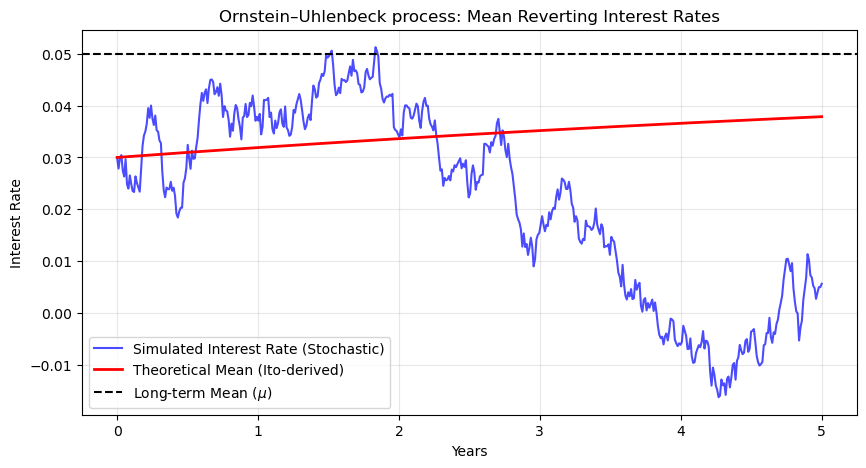

In [32]:
plt.figure(figsize=(10, 5))
plt.plot(t, r, label="Simulated Interest Rate (Stochastic)", color='blue', alpha=0.7)
plt.plot(t, expected_path, label="Theoretical Mean (Ito-derived)", color='red', lw=2)
plt.axhline(mu, color='black', linestyle='--', label="Long-term Mean ($\mu$)")
plt.title("Ornstein–Uhlenbeck process: Mean Reverting Interest Rates")
plt.xlabel("Years")
plt.ylabel("Interest Rate") 
plt.legend() 
plt.grid(True, alpha=0.3) 
plt.show()

### Why Include the Itô-Derived Theoretical Mean?




| Purpose | Description & Practical Impact |
| :--- | :--- |
| **Validation of Code & Discretization** | Serves as an exact benchmark. If the empirical average of Monte Carlo paths deviates from $E[r_t]$, it alerts us to numerical discretization errors or coding bugs. |
| **Decoupling Trend from Noise** | Isolates the deterministic macro trajectory (red line) from short-term market noise $\sigma dW_t$ (blue line), showing how gravity pulls prices back to baseline. |
| **Closed-Form Efficiency** | Proves we can compute expected future rates, forward curves, and bond prices directly using the equation, bypassing expensive computer simulations. |

---

### Core Insight

> **The Power of Itô's Lemma**: While any single market realization (blue line) is inherently unpredictable, Itô's Lemma allows us to predict the **exact deterministic average** (red line) across all possible future states.

### Summary


- model the asset price:

$$log(S_t) = \mu t +\sigma W_t $$

$$S_t = S_0 e^{\mu t +\sigma W_t} $$

- changes in the asset price can be viewed as:

$$dS_t = \mu S_t + \sigma S_t dW_t$$



### Summary

- define integration with respect to a stochastic process:



$$\int_0^T X_tdW_t = \lim_{n \rightarrow \infty} \sum_{j=0}^n X_{t_j}(W_{t_{j+1}}-W_{t_j})$$


- when $S_t$ is a drift diffusion process Ito's rule can be used to calculate the derivate:

$$f(S_T) = f(S_0) + \int_0^T \Big( \mu_ t f'(S_t)dt +  \frac{1}{2} \int_0^T \sigma_t^2 f''(S_t) \Big) dt + \int_0^T \sigma_ t f'(S_t)dW_t  $$

### We have a model for the asset price and a way to calculate changes in the portfolio value !!!

### References

- Cameron Connell, *Financial Derivatives course*, accessed on 2023 August

- Peter Kevei, *Financial mathematics lecture notes* (University of Szeged, 2020)

- QuantPy youtube channel, accessed on 2023 August

- Schumacher, J. M., *Introduction to Financial Derivatives*, (Open Press TiU, 2020)

- Tony R. Kuphaldt, *Lessons in Industrial Automation*, Control Aumation, accessed on 2023 August

- Vladimir Ilievsky, *Integrals are Fun - Illustrated Riemann-Stieltjes Integral*, iSquared, accessed on 2023 August




